# 07 – Phase 7: Brain-Region Analysis (RQ 2)

> **Research question 2:** Which neural population subsets (by brain region)
> contribute most to the transfer gains observed in Phase 6?

## What this notebook does

| Step | Description |
|------|-------------|
| 7.1 | **Region ablation** – train with one region zeroed out at a time; measure drop in Δ_causal |
| 7.2 | **Region-only alignment** – train aligned to a *single* region only; rank region utility |
| 7.3 | **Region × OOD-split heatmap** – visualise which regions help which generalisation axes |

**Inputs (Add Input):** the Phase 6 output dataset (e.g. `cdb2m-phase6`).
Must contain: `X_region.npy`, controls, `cdb2m_lib.py`, `synth_suite.npz`,
`real_stimuli.npz`, `folds.json`, `M_region.csv`, `results_raw.csv` (Phase 5 baseline).

**Settings:** Accelerator → **GPU T4**. Runtime ~60–80 min (4 ablation + 4 single-region × 3 seeds each).

In [1]:
# ---- Cell A: setup and load Phase 6 outputs ----
import os, sys, json, pathlib, warnings, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import stats as sp_stats

warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

OUT7 = pathlib.Path("/kaggle/working/phase7_out")
OUT7.mkdir(parents=True, exist_ok=True)

def find(name):
    hits = []
    for root in ("/kaggle/input", "/kaggle/working"):
        hits += sorted(pathlib.Path(root).rglob(name))
    assert hits, f"{name} not found – add the Phase 6 dataset as input"
    return hits[0]

# Locate Phase 6 root
P6 = find("results_raw.csv").parent
print("Phase 6 root:", P6)

sys.path.insert(0, str(P6))
import importlib, cdb2m_lib
importlib.reload(cdb2m_lib)
from cdb2m_lib import *

# ---- load data ----
X_real     = np.load(P6 / "X_region.npy")           # (N, 4, 16, 5)
X_maxent   = np.load(P6 / "X_maxent.npy")
X_shuffled = np.load(P6 / "X_shuffled.npy")
X_randnoise= np.load(P6 / "X_randnoise.npy")

M        = pd.read_csv(P6 / "M_region.csv")
C        = M.clean.astype(bool).values

stim      = np.load(P6 / "real_stimuli.npz", allow_pickle=True)
suite_raw = np.load(P6 / "synth_suite.npz",  allow_pickle=True)

X_tok    = stim["X_tok"];  y_tok = stim["y"];  n_tokens = int(stim["n_tokens"])
X_tok_c  = X_tok[C];      y_tok_c = y_tok[C].astype(np.int64);  N_clean = int(C.sum())

suite_keys = ["id_4_6", "size_8", "len_10", "len_12", "unseen_letters"]
ood_splits = ["size_8", "len_10", "len_12", "unseen_letters"]
suite      = {k: (suite_raw[f"{k}_X"], suite_raw[f"{k}_y"].astype(np.int64)) for k in suite_keys}

# Phase 5 baseline results (real vs controls)
results5   = pd.read_csv(P6 / "results_raw.csv")
CONTROLS   = ["maxent", "shuffled", "randnoise"]

# Region names (index 0-3)
REGIONS = CORE   # ["hippocampus","amygdala","parahippocampal","lateral_temporal"]
N_REG   = len(REGIONS)

print(f"X_real shape : {X_real.shape}  (N={N_clean} clean trials)")
print(f"Regions      : {REGIONS}")
print(f"Suite splits : {suite_keys}")
print(f"n_tokens     : {n_tokens}")

Device: cuda
Phase 6 root: /kaggle/input/datasets/rachana240906/cdb2m-phase6/phase6_out
X_real shape : (3353, 4, 16, 5)  (N=3185 clean trials)
Regions      : ['hippocampus', 'amygdala', 'parahippocampal', 'lateral_temporal']
Suite splits : ['id_4_6', 'size_8', 'len_10', 'len_12', 'unseen_letters']
n_tokens     : 22


## Shared helpers (InfoNCE, CKA, training loop)

In [2]:
# ---- Cell B: helpers ----

def infonce_loss(z, h, tau=0.07):
    z = F.normalize(z, dim=1); h = F.normalize(h, dim=1)
    logits_zh = z @ h.T / tau; logits_hz = h @ z.T / tau
    labels = torch.arange(len(z), device=z.device)
    return 0.5 * (F.cross_entropy(logits_zh, labels) + F.cross_entropy(logits_hz, labels))

def linear_cka(X, Y):
    n = X.shape[0]
    X = X - X.mean(0, keepdims=True); Y = Y - Y.mean(0, keepdims=True)
    hsic_xy = np.linalg.norm(Y.T @ X)**2 / (n-1)**2
    hsic_xx = np.linalg.norm(X.T @ X)**2 / (n-1)**2
    hsic_yy = np.linalg.norm(Y.T @ Y)**2 / (n-1)**2
    return float(hsic_xy / (np.sqrt(hsic_xx * hsic_yy) + 1e-10))

class ProjectionHead(nn.Module):
    def __init__(self, d_in=128, d_out=32):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, d_in), nn.GELU(), nn.Linear(d_in, d_out))
    def forward(self, x): return self.net(x)

def make_models(seed):
    torch.manual_seed(seed)
    gru  = SeqGRU(n_tokens).to(device)
    head = ProjectionHead().to(device)
    enc  = BrainEncoder().to(device)
    return gru, head, enc

@torch.no_grad()
def evaluate(gru, Xseq, yseq):
    gru.eval()
    pred = gru(torch.as_tensor(Xseq, device=device)).argmax(1).cpu().numpy()
    y = np.asarray(yseq)
    tp = ((pred==1)&(y==1)).sum(); pp = (y==1).sum()
    tn = ((pred==0)&(y==0)).sum(); pn = (y==0).sum()
    gru.train()
    return float(0.5*(tp/max(pp,1) + tn/max(pn,1)))

@torch.no_grad()
def compute_cka(gru, head, enc, X_brain, X_seq):
    gru.eval(); head.eval(); enc.eval()
    all_z, all_h = [], []
    for i in range(0, len(X_seq), 256):
        xb = torch.as_tensor(X_brain[i:i+256], device=device)
        xs = torch.as_tensor(X_seq[i:i+256],   device=device)
        _, hrep = gru(xs, return_rep=True)
        all_z.append(enc(xb).cpu().numpy())
        all_h.append(head(hrep).cpu().numpy())
    gru.train(); head.train(); enc.train()
    return linear_cka(np.concatenate(all_z), np.concatenate(all_h))

def train_one(X_brain_c, seed, lam=1.0, tau=0.07, steps=5000, bs=64, lr=3e-3):
    """Train one RNN+encoder run. Returns (gru, head, enc) and eval dict."""
    gru, head, enc = make_models(seed)
    params = list(gru.parameters()) + list(head.parameters()) + list(enc.parameters())
    opt    = torch.optim.Adam(params, lr=lr)
    Xt_c   = torch.as_tensor(X_tok_c, device=device)
    yt_c   = torch.as_tensor(y_tok_c, device=device)
    rng_tr = np.random.default_rng(seed + 300)
    use_align = X_brain_c is not None

    for step in range(steps):
        idx    = rng_tr.integers(0, N_clean, bs)
        logits, hrep = gru(Xt_c[idx], return_rep=True)
        t_loss = F.cross_entropy(logits, yt_c[idx])
        if use_align:
            xb   = torch.as_tensor(X_brain_c[idx], device=device)
            loss = t_loss + lam * infonce_loss(enc(xb), head(hrep), tau=tau)
        else:
            loss = t_loss
        opt.zero_grad(); loss.backward(); opt.step()

    row = {}
    for split_name, (Xs, ys) in suite.items():
        row[split_name] = evaluate(gru, Xs, ys)
    row["cka"] = compute_cka(gru, head, enc, X_real[C], X_tok_c)
    return gru, head, enc, row

print("Helpers ready. Training loop =", train_one.__doc__.strip())

Helpers ready. Training loop = Train one RNN+encoder run. Returns (gru, head, enc) and eval dict.


## 7.1 Region Ablation

For each region r, we create a modified brain tensor where region r is
**replaced with NaN** (treated as "not recorded" by the BrainEncoder mask).
We then retrain the full pipeline under real alignment and measure OOD accuracy.

**Interpretation:**  
- A large accuracy drop when region r is ablated → region r is **critical**  
- Small/no drop → region r is redundant given the others

In [3]:
# ---- Cell C: 7.1 - build ablated brain tensors ----

def ablate_region(X, region_idx):
    """Return copy of X with region region_idx set to NaN (treated as missing)."""
    X2 = X.copy()
    X2[:, region_idx, :, :] = np.nan
    return X2

def single_region(X, region_idx):
    """Return copy of X with ALL regions except region_idx set to NaN."""
    X2 = np.full_like(X, np.nan)
    X2[:, region_idx, :, :] = X[:, region_idx, :, :]
    return X2

# Sanity check: BrainEncoder handles all-NaN regions gracefully
sample = torch.as_tensor(ablate_region(X_real[C][:1], 0), device=device)
with torch.no_grad():
    test_enc = BrainEncoder().to(device)
    out = test_enc(sample)
print(f"BrainEncoder output with region 0 ablated: shape={out.shape}  (no NaN = OK: {not out.isnan().any().item()})")

# Build all ablated and single-region tensors (only the clean trials)
X_ablate = {r: ablate_region(X_real[C], r) for r in range(N_REG)}
X_single  = {r: single_region(X_real[C], r) for r in range(N_REG)}

print("\nAblated tensors (one region NaN'd out per entry):")
for r, name in enumerate(REGIONS):
    frac_nan = np.isnan(X_ablate[r][:, r]).all(axis=(1,2)).mean()
    print(f"  r={r} ({name:20s})  region{r}_all_nan={frac_nan:.1%}")

print("\nSingle-region tensors (only one region kept):")
for r, name in enumerate(REGIONS):
    frac_ok = (~np.isnan(X_single[r][:, r])).any(axis=(1,2)).mean()
    print(f"  r={r} ({name:20s})  region{r}_has_data={frac_ok:.1%}")

BrainEncoder output with region 0 ablated: shape=torch.Size([1, 32])  (no NaN = OK: True)

Ablated tensors (one region NaN'd out per entry):
  r=0 (hippocampus         )  region0_all_nan=100.0%
  r=1 (amygdala            )  region1_all_nan=100.0%
  r=2 (parahippocampal     )  region2_all_nan=100.0%
  r=3 (lateral_temporal    )  region3_all_nan=100.0%

Single-region tensors (only one region kept):
  r=0 (hippocampus         )  region0_has_data=71.3%
  r=1 (amygdala            )  region1_has_data=53.4%
  r=2 (parahippocampal     )  region2_has_data=54.3%
  r=3 (lateral_temporal    )  region3_has_data=100.0%


In [4]:
# ---- Cell D: 7.1 - ablation training (~25-35 min) ----
SEEDS = [0, 1, 2]
LAMBDA = 1.0

ablation_rows = []
t0 = time.time()
total = (N_REG + 1) * len(SEEDS)   # 4 ablations + 1 full-real baseline, 3 seeds each
run_i = 0

# -- full real baseline (all 4 regions) --
for seed in SEEDS:
    run_i += 1
    _, _, _, row = train_one(X_real[C], seed, lam=LAMBDA)
    row.update(dict(condition="real_all", ablated_region="none", seed=seed))
    ablation_rows.append(row)
    print(f"[{run_i:2d}/{total}] [{time.time()-t0:5.0f}s] real_all   s={seed}  "
          f"id={row['id_4_6']:.3f}  sz8={row['size_8']:.3f}  CKA={row['cka']:.3f}")

# -- ablate one region at a time --
for r, rname in enumerate(REGIONS):
    for seed in SEEDS:
        run_i += 1
        _, _, _, row = train_one(X_ablate[r], seed, lam=LAMBDA)
        row.update(dict(condition=f"ablate_{rname}", ablated_region=rname, seed=seed))
        ablation_rows.append(row)
        print(f"[{run_i:2d}/{total}] [{time.time()-t0:5.0f}s] ablate {rname:20s} s={seed}  "
              f"id={row['id_4_6']:.3f}  sz8={row['size_8']:.3f}  CKA={row['cka']:.3f}")

ablation_df = pd.DataFrame(ablation_rows)
ablation_df.to_csv(OUT7 / "ablation_results.csv", index=False)
print(f"\nDone. {len(ablation_df)} rows saved to ablation_results.csv")
print(ablation_df.groupby("condition")[ood_splits].mean().round(3).to_string())

[ 1/15] [   37s] real_all   s=0  id=0.740  sz8=0.670  CKA=0.708
[ 2/15] [   66s] real_all   s=1  id=0.758  sz8=0.678  CKA=0.674
[ 3/15] [   95s] real_all   s=2  id=0.697  sz8=0.653  CKA=0.705
[ 4/15] [  124s] ablate hippocampus          s=0  id=0.763  sz8=0.718  CKA=0.561
[ 5/15] [  153s] ablate hippocampus          s=1  id=0.726  sz8=0.644  CKA=0.626
[ 6/15] [  182s] ablate hippocampus          s=2  id=0.735  sz8=0.675  CKA=0.618
[ 7/15] [  211s] ablate amygdala             s=0  id=0.714  sz8=0.705  CKA=0.580
[ 8/15] [  240s] ablate amygdala             s=1  id=0.735  sz8=0.662  CKA=0.600
[ 9/15] [  269s] ablate amygdala             s=2  id=0.686  sz8=0.639  CKA=0.616
[10/15] [  298s] ablate parahippocampal      s=0  id=0.751  sz8=0.665  CKA=0.616
[11/15] [  327s] ablate parahippocampal      s=1  id=0.694  sz8=0.653  CKA=0.586
[12/15] [  356s] ablate parahippocampal      s=2  id=0.735  sz8=0.648  CKA=0.613
[13/15] [  385s] ablate lateral_temporal     s=0  id=0.690  sz8=0.646  CKA=0.56

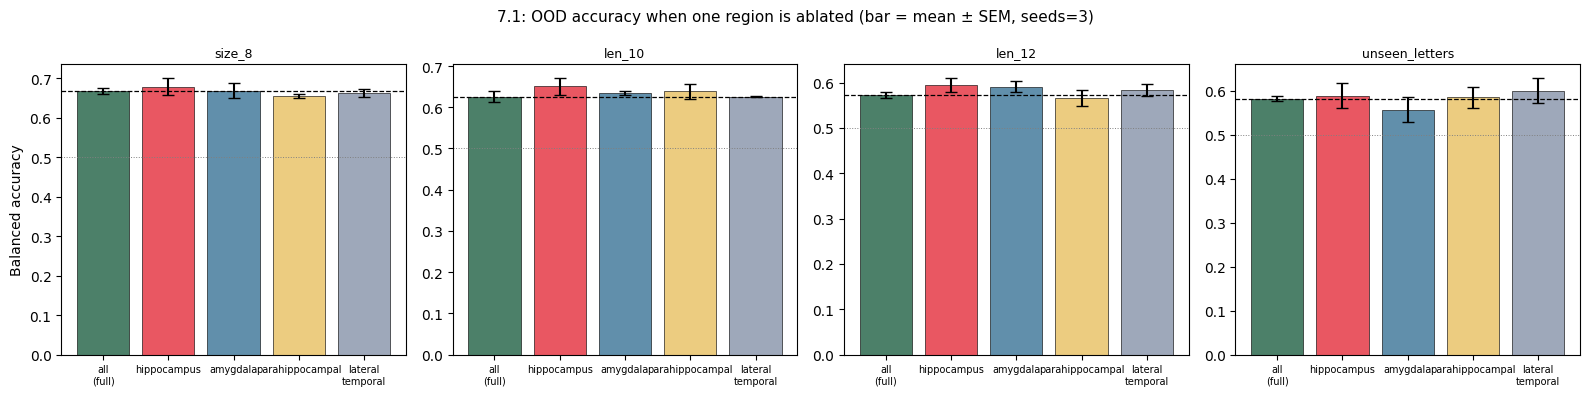

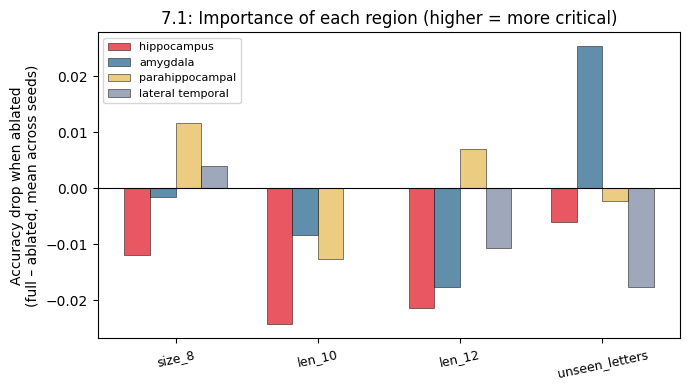

Ablation figures saved.


In [5]:
# ---- Cell E: 7.1 - ablation figures ----
REG_COLORS = {
    "none":                "#2d6a4f",
    "hippocampus":         "#e63946",
    "amygdala":            "#457b9d",
    "parahippocampal":     "#e9c46a",
    "lateral_temporal":    "#8d99ae",
}

# Fig 1: OOD accuracy by ablated region (bar chart)
fig, axes = plt.subplots(1, len(ood_splits), figsize=(16, 4), sharey=False)
cond_order = ["none"] + REGIONS

for ax, split in zip(axes, ood_splits):
    means, sems, colors = [], [], []
    for rname in cond_order:
        sub = ablation_df[ablation_df.ablated_region == rname][split]
        means.append(sub.mean()); sems.append(sub.sem())
        colors.append(REG_COLORS[rname])
    x_pos = np.arange(len(cond_order))
    ax.bar(x_pos, means, yerr=sems, capsize=4,
           color=colors, edgecolor="k", linewidth=0.5, alpha=0.85)
    ax.axhline(ablation_df[ablation_df.ablated_region=="none"][split].mean(),
               color="k", ls="--", lw=0.9, label="full")
    ax.axhline(0.5, color="grey", ls=":", lw=0.7)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(["all\n(full)"] + [r.replace("_","\n") for r in REGIONS], fontsize=7)
    ax.set_title(split, fontsize=9)
    ax.set_ylabel("Balanced accuracy" if ax is axes[0] else "")

fig.suptitle("7.1: OOD accuracy when one region is ablated (bar = mean ± SEM, seeds=3)", fontsize=11)
plt.tight_layout()
plt.savefig(OUT7 / "fig_ablation_acc.png", dpi=150); plt.show()

# Fig 2: Accuracy drop vs full-real for each region × OOD split
full_mean   = ablation_df[ablation_df.ablated_region=="none"][ood_splits].mean()
drop_rows   = []
for rname in REGIONS:
    sub = ablation_df[ablation_df.ablated_region==rname][ood_splits].mean()
    drop_rows.append({"region": rname, **{s: full_mean[s]-sub[s] for s in ood_splits}})
drop_df = pd.DataFrame(drop_rows).set_index("region")
drop_df.to_csv(OUT7 / "ablation_drop.csv")

fig, ax = plt.subplots(figsize=(7, 4))
x_pos = np.arange(len(ood_splits))
bar_w = 0.18
for i, rname in enumerate(REGIONS):
    ax.bar(x_pos + i*bar_w, drop_df.loc[rname, ood_splits],
           width=bar_w, label=rname.replace("_"," "),
           color=REG_COLORS[rname], edgecolor="k", linewidth=0.4, alpha=0.85)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x_pos + bar_w*1.5); ax.set_xticklabels(ood_splits, rotation=12, fontsize=9)
ax.set_ylabel("Accuracy drop when ablated\n(full – ablated, mean across seeds)")
ax.set_title("7.1: Importance of each region (higher = more critical)")
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(OUT7 / "fig_ablation_drop.png", dpi=150); plt.show()
print("Ablation figures saved.")

## 7.2 Region-Only Alignment

Here we align the model to a **single region** in isolation — all other regions
are masked to NaN so the BrainEncoder only "sees" one region.

This answers: *if we could only pick one brain region to align to, which would be most valuable?*

In [6]:
# ---- Cell F: 7.2 - single-region training (~25-35 min) ----
single_rows = []
total2 = N_REG * len(SEEDS)
run_i2 = 0
t0 = time.time()

for r, rname in enumerate(REGIONS):
    for seed in SEEDS:
        run_i2 += 1
        _, _, _, row = train_one(X_single[r], seed, lam=LAMBDA)
        row.update(dict(condition=f"single_{rname}", single_region=rname, seed=seed))
        single_rows.append(row)
        print(f"[{run_i2:2d}/{total2}] [{time.time()-t0:5.0f}s] single {rname:20s} s={seed}  "
              f"id={row['id_4_6']:.3f}  sz8={row['size_8']:.3f}  CKA={row['cka']:.3f}")

single_df = pd.DataFrame(single_rows)
single_df.to_csv(OUT7 / "single_region_results.csv", index=False)
print(f"\nDone. {len(single_df)} rows saved to single_region_results.csv")
print(single_df.groupby("single_region")[ood_splits + ["cka"]].mean().round(3).to_string())

[ 1/12] [   29s] single hippocampus          s=0  id=0.734  sz8=0.689  CKA=0.294
[ 2/12] [   58s] single hippocampus          s=1  id=0.721  sz8=0.690  CKA=0.324
[ 3/12] [   87s] single hippocampus          s=2  id=0.696  sz8=0.647  CKA=0.256
[ 4/12] [  116s] single amygdala             s=0  id=0.733  sz8=0.645  CKA=0.295
[ 5/12] [  145s] single amygdala             s=1  id=0.720  sz8=0.664  CKA=0.461
[ 6/12] [  174s] single amygdala             s=2  id=0.711  sz8=0.664  CKA=0.455
[ 7/12] [  203s] single parahippocampal      s=0  id=0.702  sz8=0.658  CKA=0.356
[ 8/12] [  233s] single parahippocampal      s=1  id=0.743  sz8=0.672  CKA=0.275
[ 9/12] [  262s] single parahippocampal      s=2  id=0.708  sz8=0.678  CKA=0.476
[10/12] [  291s] single lateral_temporal     s=0  id=0.691  sz8=0.625  CKA=0.362
[11/12] [  320s] single lateral_temporal     s=1  id=0.701  sz8=0.664  CKA=0.394
[12/12] [  349s] single lateral_temporal     s=2  id=0.703  sz8=0.644  CKA=0.400

Done. 12 rows saved to sing

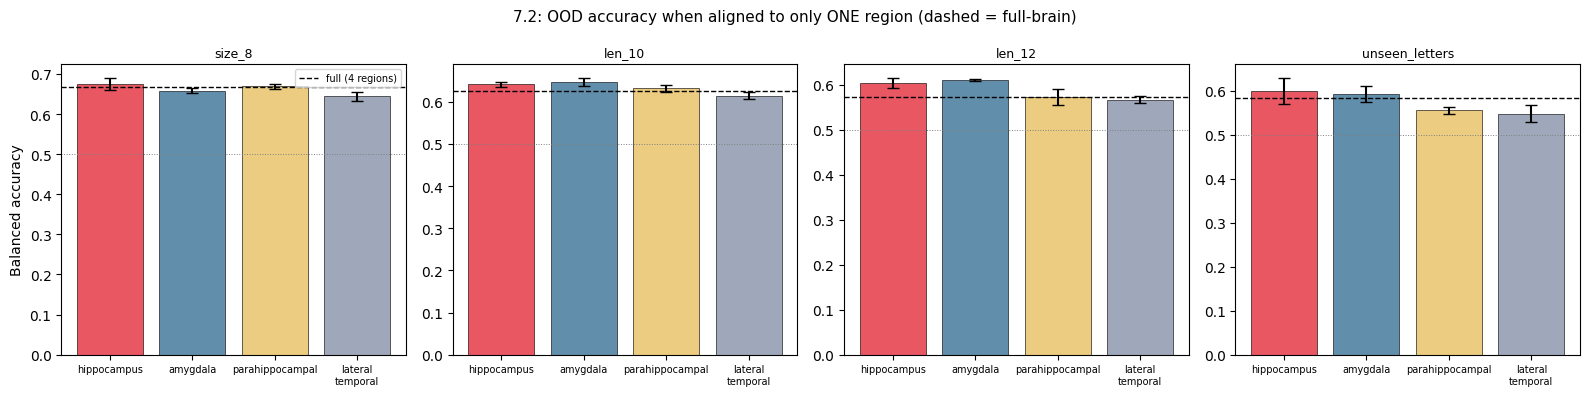

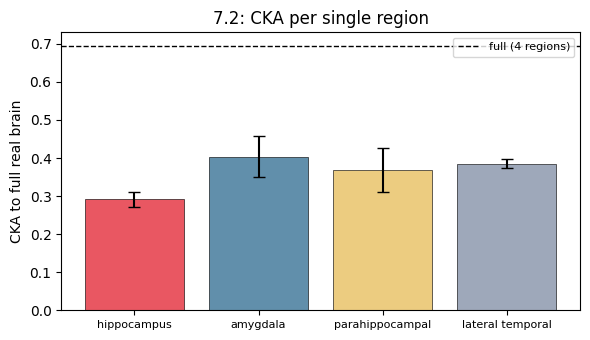

Single-region figures saved.


In [7]:
# ---- Cell G: 7.2 - single-region figures ----

# Fig 1: OOD accuracy per single region
fig, axes = plt.subplots(1, len(ood_splits), figsize=(16, 4), sharey=False)
for ax, split in zip(axes, ood_splits):
    means = [single_df[single_df.single_region==r][split].mean() for r in REGIONS]
    sems  = [single_df[single_df.single_region==r][split].sem()  for r in REGIONS]
    colors= [REG_COLORS[r] for r in REGIONS]
    ax.bar(range(N_REG), means, yerr=sems, capsize=4,
           color=colors, edgecolor="k", linewidth=0.5, alpha=0.85)
    # add full-real baseline as dashed line
    ax.axhline(ablation_df[ablation_df.ablated_region=="none"][split].mean(),
               color="k", ls="--", lw=1.0, label="full (4 regions)")
    ax.axhline(0.5, color="grey", ls=":", lw=0.7)
    ax.set_xticks(range(N_REG))
    ax.set_xticklabels([r.replace("_","\n") for r in REGIONS], fontsize=7)
    ax.set_title(split, fontsize=9)
    ax.set_ylabel("Balanced accuracy" if ax is axes[0] else "")
    if ax is axes[0]: ax.legend(fontsize=7)

fig.suptitle("7.2: OOD accuracy when aligned to only ONE region (dashed = full-brain)", fontsize=11)
plt.tight_layout()
plt.savefig(OUT7 / "fig_single_region_acc.png", dpi=150); plt.show()

# Fig 2: CKA per single region
fig, ax = plt.subplots(figsize=(6, 3.5))
cka_means = [single_df[single_df.single_region==r]["cka"].mean() for r in REGIONS]
cka_sems  = [single_df[single_df.single_region==r]["cka"].sem()  for r in REGIONS]
ax.bar(range(N_REG), cka_means, yerr=cka_sems, capsize=4,
       color=[REG_COLORS[r] for r in REGIONS], edgecolor="k", linewidth=0.5, alpha=0.85)
ax.axhline(ablation_df[ablation_df.ablated_region=="none"]["cka"].mean(),
           color="k", ls="--", lw=1.0, label="full (4 regions)")
ax.set_xticks(range(N_REG)); ax.set_xticklabels([r.replace("_"," ") for r in REGIONS], fontsize=8)
ax.set_ylabel("CKA to full real brain"); ax.set_title("7.2: CKA per single region")
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(OUT7 / "fig_single_region_cka.png", dpi=150); plt.show()
print("Single-region figures saved.")

## 7.3 Region × OOD-Split Heatmap

Combines ablation and single-region results into a **2-panel heatmap**:
- Left: Δ_causal contribution per region (ablation drop)
- Right: Accuracy when only that region is used (region utility)

This reveals whether different regions specialise for different types of generalisation.

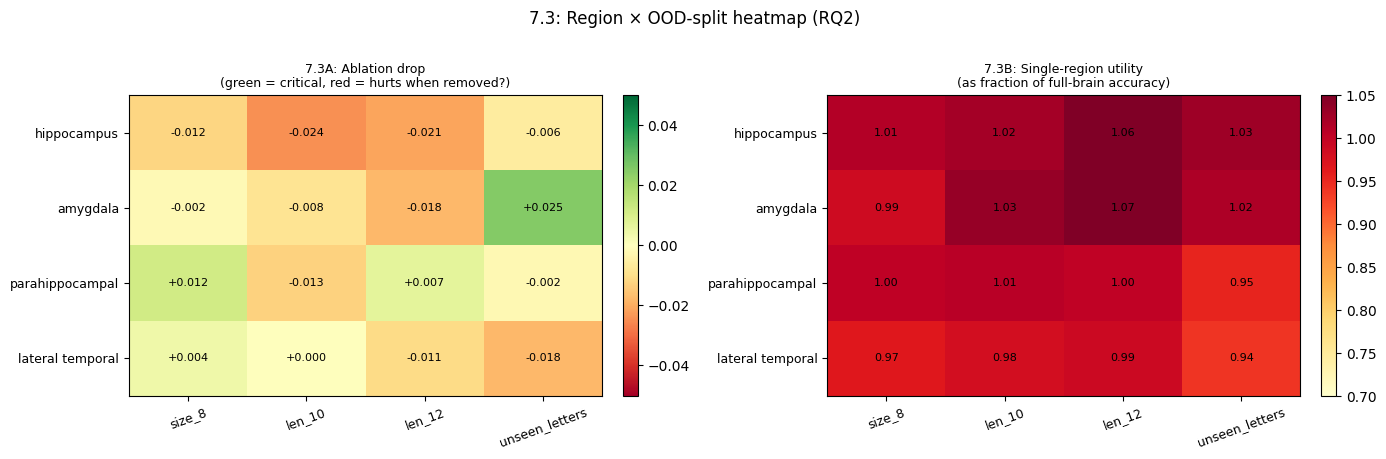

Heatmap saved.


In [8]:
# ---- Cell H: 7.3 - region × split heatmaps ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# ---- Panel A: ablation drop (how much accuracy falls when region is removed) ----
abl_matrix = drop_df[ood_splits].values    # (4 regions, 4 splits)

im0 = axes[0].imshow(abl_matrix, aspect="auto", cmap="RdYlGn",
                      vmin=-0.05, vmax=0.05)
axes[0].set_xticks(range(len(ood_splits))); axes[0].set_xticklabels(ood_splits, rotation=20, fontsize=9)
axes[0].set_yticks(range(N_REG)); axes[0].set_yticklabels([r.replace("_"," ") for r in REGIONS], fontsize=9)
axes[0].set_title("7.3A: Ablation drop\n(green = critical, red = hurts when removed?)", fontsize=9)
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
for i in range(N_REG):
    for j in range(len(ood_splits)):
        axes[0].text(j, i, f"{abl_matrix[i,j]:+.3f}", ha="center", va="center",
                    fontsize=8, color="black")

# ---- Panel B: single-region accuracy (how useful each region is alone) ----
single_matrix = np.array([
    [single_df[single_df.single_region==r][s].mean() for s in ood_splits]
    for r in REGIONS
])                                         # (4 regions, 4 splits)

full_baseline = np.array([ablation_df[ablation_df.ablated_region=="none"][s].mean()
                           for s in ood_splits])
# show as fraction of full-brain performance
frac_matrix = single_matrix / (full_baseline + 1e-8)

im1 = axes[1].imshow(frac_matrix, aspect="auto", cmap="YlOrRd", vmin=0.7, vmax=1.05)
axes[1].set_xticks(range(len(ood_splits))); axes[1].set_xticklabels(ood_splits, rotation=20, fontsize=9)
axes[1].set_yticks(range(N_REG)); axes[1].set_yticklabels([r.replace("_"," ") for r in REGIONS], fontsize=9)
axes[1].set_title("7.3B: Single-region utility\n(as fraction of full-brain accuracy)", fontsize=9)
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
for i in range(N_REG):
    for j in range(len(ood_splits)):
        axes[1].text(j, i, f"{frac_matrix[i,j]:.2f}", ha="center", va="center",
                    fontsize=8, color="black")

fig.suptitle("7.3: Region × OOD-split heatmap (RQ2)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUT7 / "fig_region_split_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Heatmap saved.")

# also save raw matrices
pd.DataFrame(abl_matrix,    index=REGIONS, columns=ood_splits).to_csv(OUT7 / "ablation_drop_matrix.csv")
pd.DataFrame(frac_matrix,   index=REGIONS, columns=ood_splits).to_csv(OUT7 / "single_region_frac_matrix.csv")
pd.DataFrame(single_matrix, index=REGIONS, columns=ood_splits).to_csv(OUT7 / "single_region_acc_matrix.csv")

In [9]:
# ---- Cell I: 7.3 - region importance ranking ----
print("=" * 60)
print("REGION IMPORTANCE RANKING (RQ2)")
print("=" * 60)

# Rank by: mean ablation drop across OOD splits (higher = more important)
rank_abl  = drop_df[ood_splits].mean(axis=1).sort_values(ascending=False)

# Rank by: mean single-region OOD accuracy (higher = more informative alone)
single_ood_mean = {r: single_df[single_df.single_region==r][ood_splits].mean().mean()
                   for r in REGIONS}
rank_single = pd.Series(single_ood_mean).sort_values(ascending=False)

print("\n--- By ablation drop (higher = more critical for transfer) ---")
for reg, drop in rank_abl.items():
    print(f"  {reg:22s}  mean OOD drop = {drop:+.4f}")

print("\n--- By single-region OOD accuracy (higher = more informative alone) ---")
for reg, acc in rank_single.items():
    print(f"  {reg:22s}  mean OOD acc  = {acc:.4f}")

# Summary table
summary_df = pd.DataFrame({
    "ablation_drop_mean_ood": rank_abl,
    "single_region_ood_mean": rank_single,
})
summary_df["rank_ablation"]     = summary_df["ablation_drop_mean_ood"].rank(ascending=False).astype(int)
summary_df["rank_single"]       = summary_df["single_region_ood_mean"].rank(ascending=False).astype(int)
summary_df["composite_rank"]    = (summary_df["rank_ablation"] + summary_df["rank_single"])
summary_df = summary_df.sort_values("composite_rank")

print("\n--- Composite ranking (lower score = more important) ---")
print(summary_df.round(4).to_string())
summary_df.to_csv(OUT7 / "region_importance_ranking.csv")
print("\nSaved region_importance_ranking.csv")

REGION IMPORTANCE RANKING (RQ2)

--- By ablation drop (higher = more critical for transfer) ---
  parahippocampal         mean OOD drop = +0.0009
  amygdala                mean OOD drop = -0.0006
  lateral_temporal        mean OOD drop = -0.0061
  hippocampus             mean OOD drop = -0.0159

--- By single-region OOD accuracy (higher = more informative alone) ---
  hippocampus             mean OOD acc  = 0.6298
  amygdala                mean OOD acc  = 0.6272
  parahippocampal         mean OOD acc  = 0.6074
  lateral_temporal        mean OOD acc  = 0.5932

--- Composite ranking (lower score = more important) ---
                  ablation_drop_mean_ood  single_region_ood_mean  rank_ablation  rank_single  composite_rank
amygdala                         -0.0006                  0.6272              2            2               4
parahippocampal                   0.0009                  0.6074              1            3               4
hippocampus                      -0.0159          

## Statistics: Are ablation drops significant?

Paired t-test: full-real accuracy vs ablated accuracy (paired by seed).

In [10]:
# ---- Cell J: significance of ablation drops ----
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

stat_rows = []
full_vals_by_seed = {seed: ablation_df[(ablation_df.ablated_region=="none") &
                                        (ablation_df.seed==seed)].iloc[0]
                     for seed in SEEDS}

for rname in REGIONS:
    for split in ood_splits:
        full_accs = np.array([full_vals_by_seed[s][split] for s in SEEDS])
        abl_accs  = np.array([ablation_df[(ablation_df.ablated_region==rname) &
                                          (ablation_df.seed==s)].iloc[0][split]
                               for s in SEEDS])
        diff = full_accs - abl_accs
        if np.std(diff) > 0:
            t, p = ttest_rel(full_accs, abl_accs)
        else:
            t, p = np.nan, np.nan
        d = np.mean(diff) / (np.std(diff, ddof=1) + 1e-10)
        stat_rows.append(dict(region=rname, split=split,
                              mean_drop=np.mean(diff), cohens_d=d,
                              t_stat=t, p_raw=p))

stat_df = pd.DataFrame(stat_rows)
reject, pvals_corr, _, _ = multipletests(stat_df["p_raw"].fillna(1.0), alpha=0.05, method="fdr_bh")
stat_df["p_fdr"] = pvals_corr
stat_df["significant"] = reject

print("=== Ablation drop significance (FDR-corrected, BH) ===")
print(stat_df.to_string(index=False, float_format="%.4f"))
stat_df.to_csv(OUT7 / "ablation_stats.csv", index=False)
print("\nSaved ablation_stats.csv")

=== Ablation drop significance (FDR-corrected, BH) ===
          region          split  mean_drop  cohens_d  t_stat  p_raw  p_fdr  significant
     hippocampus         size_8    -0.0120   -0.2864 -0.4960 0.6690 0.9927        False
     hippocampus         len_10    -0.0243   -0.5748 -0.9955 0.4244 0.9927        False
     hippocampus         len_12    -0.0213   -0.8365 -1.4489 0.2844 0.9927        False
     hippocampus unseen_letters    -0.0060   -0.1059 -0.1834 0.8714 0.9927        False
        amygdala         size_8    -0.0017   -0.0577 -0.0999 0.9295 0.9927        False
        amygdala         len_10    -0.0083   -0.2864 -0.4961 0.6690 0.9927        False
        amygdala         len_12    -0.0177   -0.6153 -1.0658 0.3982 0.9927        False
        amygdala unseen_letters     0.0253    0.4981  0.8628 0.4792 0.9927        False
 parahippocampal         size_8     0.0117    1.0104  1.7500 0.2222 0.9927        False
 parahippocampal         len_10    -0.0127   -0.2468 -0.4275 0.71

## Summary & RQ2 Answer

In [11]:
# ---- Cell K: Phase 7 summary and carry-forward ----
import shutil

print("=" * 70)
print("PHASE 7: BRAIN-REGION ANALYSIS – SUMMARY")
print("=" * 70)

# Most important region
top_region = summary_df.index[0]
print(f"\nTop region by composite rank: {top_region}")
print(f"  Ablation drop (mean OOD): {summary_df.loc[top_region,'ablation_drop_mean_ood']:+.4f}")
print(f"  Single-region OOD acc:    {summary_df.loc[top_region,'single_region_ood_mean']:.4f}")

# Significant ablations
n_sig = stat_df.significant.sum()
print(f"\nSignificant ablation drops (FDR alpha=0.05): {n_sig}/{len(stat_df)}")
for _, row in stat_df[stat_df.significant].iterrows():
    print(f"  {row.region:22s} x {row.split:12s}  drop={row.mean_drop:+.4f}  d={row.cohens_d:.2f}  p_fdr={row.p_fdr:.4f}")

# RQ2 answer
critical = stat_df.groupby("region")["significant"].sum().sort_values(ascending=False)
rq2_answer = critical.index[0] if critical.iloc[0] > 0 else "unclear"
print(f"\n>>> RQ2 Verdict: '{rq2_answer}' shows the most significant contribution to transfer gains.")

# Carry forward artifacts
p6_files = ["X_region.npy","X_maxent.npy","X_shuffled.npy","X_randnoise.npy",
            "M_region.csv","folds.json","fold_summary.csv",
            "real_stimuli.npz","synth_suite.npz","ceiling_check.csv",
            "cdb2m_lib.py","results_raw.csv","delta_b2m.csv",
            "cka_summary.csv","results_summary.csv",
            "delta_causal_perseed.csv","lambda_sweep_raw.csv","lambda_sweep_delta.csv",
            "bootstrap_ci.csv","fdr_results.csv","cka_regression.csv"]
for fname in p6_files:
    src = P6 / fname
    if src.exists(): shutil.copy(src, OUT7 / fname)

ckpt_src = P6 / "checkpoints"
if ckpt_src.exists():
    ckpt_dst = OUT7 / "checkpoints"
    if ckpt_dst.exists(): shutil.rmtree(ckpt_dst)
    shutil.copytree(ckpt_src, ckpt_dst)
    print(f"\nCopied checkpoints/ ({sum(1 for _ in ckpt_src.iterdir())} files)")

print("\n=== Phase 7 Checklist ===")
checks = {
    "7.1 Ablation training done":       (OUT7/"ablation_results.csv").exists(),
    "7.1 Ablation drop matrix saved":   (OUT7/"ablation_drop_matrix.csv").exists(),
    "7.2 Single-region training done":  (OUT7/"single_region_results.csv").exists(),
    "7.2 Fraction matrix saved":        (OUT7/"single_region_frac_matrix.csv").exists(),
    "7.3 Region×split heatmap saved":   (OUT7/"fig_region_split_heatmap.png").exists(),
    "Region importance ranking saved":  (OUT7/"region_importance_ranking.csv").exists(),
    "Ablation statistics saved":        (OUT7/"ablation_stats.csv").exists(),
}
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'} - {k}")

print(f"\n=== Files in {OUT7} ===")
for p in sorted(OUT7.iterdir()):
    if p.is_file():
        print(f"  {p.name:42s}  {p.stat().st_size/1e6:6.2f} MB")
    elif p.is_dir():
        print(f"  {p.name+'/':42s}  ({sum(1 for _ in p.iterdir())} files)")

print("\nNext: Save Version -> Output -> New Dataset (e.g. cdb2m-phase7) -> use as input for Phase 8.")

PHASE 7: BRAIN-REGION ANALYSIS – SUMMARY

Top region by composite rank: amygdala
  Ablation drop (mean OOD): -0.0006
  Single-region OOD acc:    0.6272

Significant ablation drops (FDR alpha=0.05): 0/16

>>> RQ2 Verdict: 'unclear' shows the most significant contribution to transfer gains.

Copied checkpoints/ (15 files)

=== Phase 7 Checklist ===
  PASS - 7.1 Ablation training done
  PASS - 7.1 Ablation drop matrix saved
  PASS - 7.2 Single-region training done
  PASS - 7.2 Fraction matrix saved
  PASS - 7.3 Region×split heatmap saved
  PASS - Region importance ranking saved
  PASS - Ablation statistics saved

=== Files in /kaggle/working/phase7_out ===
  M_region.csv                                  0.23 MB
  X_maxent.npy                                  4.29 MB
  X_randnoise.npy                               4.29 MB
  X_region.npy                                  4.29 MB
  X_shuffled.npy                                4.29 MB
  ablation_drop.csv                             0.00 MB
  